Protein clusters: 1164
Peptides: 8378
Heaps' law fit: k = 988.831, alpha = 0.031, 95% interval = [0.027, 0.038], RMSD = 3.466
Clusters: k = 988.831, alpha = 0.031


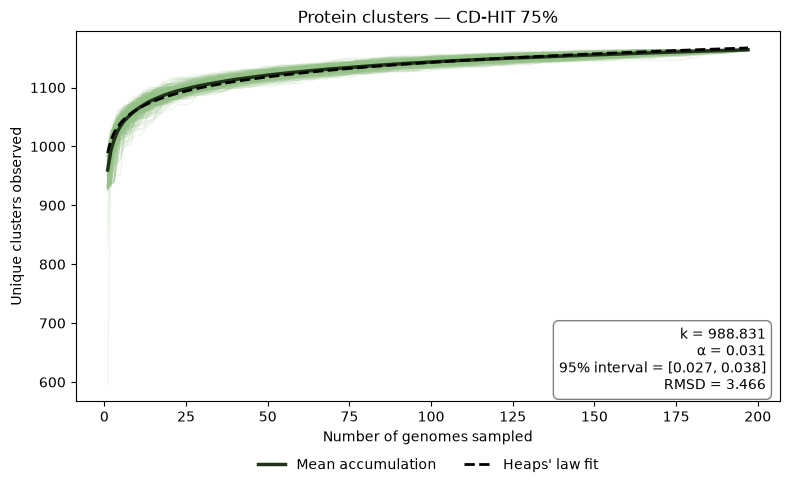

Heaps' law fit: k = 7708.627, alpha = 0.016, 95% interval = [0.013, 0.021], RMSD = 16.466
Peptides: k = 7708.627, alpha = 0.016


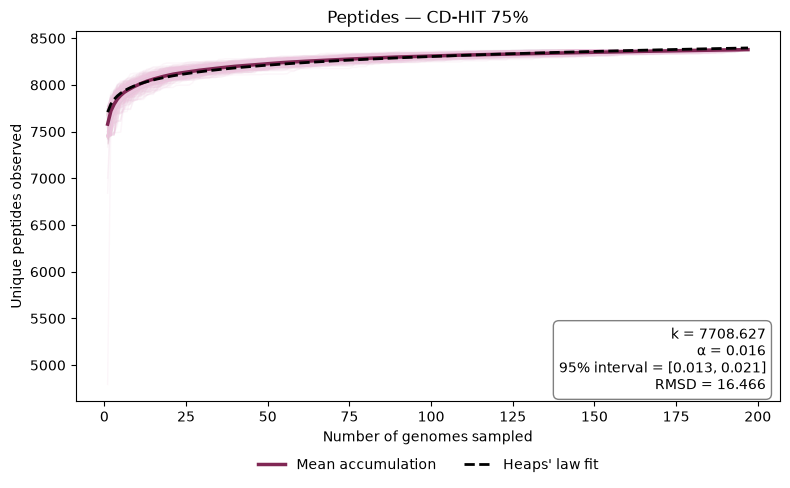

(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Peptides — CD-HIT 75%'}, xlabel='Number of genomes sampled', ylabel='Unique peptides observed'>)

In [21]:
import ast
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import curve_fit


# ============================================================
# Parameters
# ============================================================

cdhit = 75
pathogen='dysgalactiae'
frag_dir = (
    "../../../../dysgalactiae_data/fragpipe_output/"
    f"{pathogen}/cdhit_{cdhit}_{pathogen}"
)

cluster_frame_path = (
    "../../../data/manuscript/"
    f"{pathogen}/cdhit_{cdhit}_{pathogen}/"
    f"{pathogen}_alias_cluster_{cdhit}cluster_frame.csv"
)


# ============================================================
# Load cluster information
# ============================================================

cluster_frame = pd.read_csv(
    cluster_frame_path,
    index_col=0
)

cluster_frame["genomes"] = (
    cluster_frame["genomes"]
    .astype(object)
    .apply(ast.literal_eval)
)


# ============================================================
# Load DDA proteins
# ============================================================

DDA = pd.read_csv(
    f"{frag_dir}/protein.tsv",
    sep="\t"
)

proteins = [
    protein[7:]
    for protein in DDA["Protein"].dropna()
]


# Keep clusters represented in the proteomic dataset
clusters = cluster_frame.loc[
    cluster_frame["seguid reference"].isin(proteins)
].copy()


# ============================================================
# Genome IDs
# ============================================================

genome_ids = sorted({
    genome
    for genomes in clusters["genomes"]
    for genome in genomes
})


print(f"Protein clusters: {len(clusters)}")


# ============================================================
# Load peptides
# ============================================================

peptides = pd.read_csv(
    f"{frag_dir}/peptide.tsv",
    sep="\t"
)


# Extract representative protein ID
peptides["seguid reference"] = (
    peptides["Protein"]
    .str.replace("sequid:", "", regex=False)
    .str.split(";")
    .str[0]
)


# Map protein cluster -> genomes
seguid_to_genomes = dict(
    zip(
        clusters["seguid reference"],
        clusters["genomes"]
    )
)

peptides["genomes"] = (
    peptides["seguid reference"]
    .map(seguid_to_genomes)
)


# Remove peptides without genome information
peptides = peptides.dropna(
    subset=["genomes"]
).copy()

print(f"Peptides: {len(peptides)}")


# ============================================================
# Heaps' law analysis
# ============================================================

def heaps_law_power_analysis(
    features,
    genome_ids,
    n_iter=300,
    random_seed=42,
):
    """
    Calculate accumulation curves for unique features
    across randomly ordered genomes.
    """

    feature_genomes = features["genomes"].apply(set)

    genome_ids = list(genome_ids)
    n_genomes = len(genome_ids)

    rng = random.Random(random_seed)

    results = np.zeros(
        (n_iter, n_genomes),
        dtype=int
    )

    for i in range(n_iter):

        seen_features = set()

        genome_order = rng.sample(
            genome_ids,
            n_genomes
        )

        for j, genome_id in enumerate(genome_order):

            present = feature_genomes.apply(
                lambda genomes: genome_id in genomes
            )

            seen_features.update(
                features.index[present]
            )

            results[i, j] = len(seen_features)

    mean_curve = results.mean(axis=0)
    std_curve = results.std(axis=0)

    return mean_curve, std_curve, results


# ============================================================
# Heaps' law model
# ============================================================

def heaps_powerlaw(x, k, alpha):

    return k * np.power(
        x,
        alpha
    )


# ============================================================
# Fit Heaps' law
# ============================================================

def fit_heaps_law(mean_curve, all_curves):

    x = np.arange(
        1,
        len(mean_curve) + 1
    )

    y = mean_curve

    # --------------------------------------------------------
    # Fit to mean accumulation curve
    # --------------------------------------------------------

    popt, _ = curve_fit(
        heaps_powerlaw,
        x,
        y,
        bounds=(0, [np.inf, 2])
    )

    k_fit, alpha_fit = popt

    y_fit = heaps_powerlaw(
        x,
        k_fit,
        alpha_fit
    )

    # --------------------------------------------------------
    # RMSD
    # --------------------------------------------------------

    rmsd = np.sqrt(
        np.mean(
            (y - y_fit) ** 2
        )
    )

    # --------------------------------------------------------
    # Alpha distribution across iterations
    # --------------------------------------------------------

    alphas = []

    for curve in all_curves:

        try:
            popt_iter, _ = curve_fit(
                heaps_powerlaw,
                x,
                curve,
                bounds=(0, [np.inf, 2])
            )

            alphas.append(
                popt_iter[1]
            )

        except RuntimeError:
            continue

    alphas = np.asarray(alphas)

    alpha_ci_lower = np.percentile(
        alphas,
        2.5
    )

    alpha_ci_upper = np.percentile(
        alphas,
        97.5
    )

    print(
        f"Heaps' law fit: "
        f"k = {k_fit:.3f}, "
        f"alpha = {alpha_fit:.3f}, "
        f"95% interval = "
        f"[{alpha_ci_lower:.3f}, {alpha_ci_upper:.3f}], "
        f"RMSD = {rmsd:.3f}"
    )

    return (
        popt,
        rmsd,
        alpha_ci_lower,
        alpha_ci_upper,
        alphas
    )


# ============================================================
# Plotting
# ============================================================

def plot_heaps_law(
    mean_curve,
    std_curve,
    all_curves,
    popt,
    rmsd,
    alpha_ci_lower,
    alpha_ci_upper,
    ylabel,
    title,
    color,
    light_color,
    filename=None,
):

    k_fit, alpha_fit = popt

    x = np.arange(
        1,
        len(mean_curve) + 1
    )

    y_fit = heaps_powerlaw(
        x,
        k_fit,
        alpha_fit
    )

    fig, ax = plt.subplots(
        figsize=(8, 5),
        facecolor="white"
    )

    ax.set_facecolor("white")

    # Individual accumulation curves
    for curve in all_curves:
        ax.plot(
            x,
            curve,
            color=light_color,
            alpha=0.15,
            linewidth=1
        )

    # Mean accumulation curve
    ax.plot(
        x,
        mean_curve,
        color=color,
        linewidth=2.5,
        label="Mean accumulation"
    )

    # Standard deviation
    ax.fill_between(
        x,
        mean_curve - std_curve,
        mean_curve + std_curve,
        color=color,
        alpha=0.15
    )

    # Heaps' law fit
    ax.plot(
        x,
        y_fit,
        color="black",
        linestyle="--",
        linewidth=2,
        label="Heaps' law fit"
    )

    ax.set_xlabel(
        "Number of genomes sampled",
        color="black"
    )

    ax.set_ylabel(
        ylabel,
        color="black"
    )

    ax.set_title(
        title,
        color="black"
    )

    ax.tick_params(
        axis="both",
        colors="black"
    )

    # Fit statistics
    ax.text(
        0.98,
        0.02,
        f"k = {k_fit:.3f}\n"
        f"α = {alpha_fit:.3f}\n"
        f"95% interval = [{alpha_ci_lower:.3f}, "
        f"{alpha_ci_upper:.3f}]\n"
        f"RMSD = {rmsd:.3f}",
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        color="black",
        fontsize=10,
        bbox=dict(
            boxstyle="round,pad=0.4",
            facecolor="white",
            edgecolor="gray"
        )
    )

    legend = ax.legend(
        frameon=False,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.12),
        ncol=2
    )

    for text in legend.get_texts():
        text.set_color("black")

    for spine in ax.spines.values():
        spine.set_color("black")

    ax.grid(False)

    fig.tight_layout()

    if filename is not None:
        fig.savefig(
            filename,
            dpi=600,
            bbox_inches="tight",
            facecolor="white"
        )

    plt.show()

    return fig, ax


# ============================================================
# Protein clusters
# ============================================================

mean_clusters, std_clusters, curves_clusters = (
    heaps_law_power_analysis(
        clusters,
        genome_ids,
        n_iter=300,
        random_seed=42
    )
)

(
    popt_clusters,
    rmsd_clusters,
    alpha_ci_lower_clusters,
    alpha_ci_upper_clusters,
    alphas_clusters
) = fit_heaps_law(
    mean_clusters,
    curves_clusters
)

print(
    f"Clusters: "
    f"k = {popt_clusters[0]:.3f}, "
    f"alpha = {popt_clusters[1]:.3f}"
)

plot_heaps_law(
    mean_curve=mean_clusters,
    std_curve=std_clusters,
    all_curves=curves_clusters,
    popt=popt_clusters,
    rmsd=rmsd_clusters,
    alpha_ci_lower=alpha_ci_lower_clusters,
    alpha_ci_upper=alpha_ci_upper_clusters,
    ylabel="Unique clusters observed",
    title=f"Protein clusters — CD-HIT {cdhit}%",
    color="#20331a",
    light_color="#94c186",
    filename=f"heaps_clusters_cdhit_{cdhit}_{pathogen}.png"
)


# ============================================================
# Peptides
# ============================================================

mean_peptides, std_peptides, curves_peptides = (
    heaps_law_power_analysis(
        peptides,
        genome_ids,
        n_iter=300,
        random_seed=42
    )
)

(
    popt_peptides,
    rmsd_peptides,
    alpha_ci_lower_peptides,
    alpha_ci_upper_peptides,
    alphas_peptides
) = fit_heaps_law(
    mean_peptides,
    curves_peptides
)

print(
    f"Peptides: "
    f"k = {popt_peptides[0]:.3f}, "
    f"alpha = {popt_peptides[1]:.3f}"
)

plot_heaps_law(
    mean_curve=mean_peptides,
    std_curve=std_peptides,
    all_curves=curves_peptides,
    popt=popt_peptides,
    rmsd=rmsd_peptides,
    alpha_ci_lower=alpha_ci_lower_peptides,
    alpha_ci_upper=alpha_ci_upper_peptides,
    ylabel="Unique peptides observed",
    title=f"Peptides — CD-HIT {cdhit}%",
    color="#802754",
    light_color="#ecc5dd",
    filename=f"heaps_peptides_cdhit_{cdhit}_{pathogen}.png"
)

# Marginal gain from the last added genome

In [22]:
def marginal_accumulation(k, alpha, N):
    current = k * N**alpha
    next_genome = k * (N + 1)**alpha

    absolute_gain = next_genome - current
    relative_gain = absolute_gain / current

    return absolute_gain, relative_gain

In [27]:
absolute_gain, relative_gain = marginal_accumulation(
    k_fit,
    alpha_fit,
    N=193
)

print("Average new features per additional genome:", absolute_gain)
print("Relative increase:", relative_gain * 100, "%")

Average new features per additional genome: 0.1892308285719082
Relative increase: 0.016222918924090387 %


In [24]:
def calculate_marginal_gain(k, alpha, N):
    """
    Calculate the expected increase in unique features
    when increasing the number of genomes from N to N+1.
    """

    V_N = k * N**alpha
    V_N_plus_1 = k * (N + 1)**alpha

    absolute_gain = V_N_plus_1 - V_N
    relative_gain = absolute_gain / V_N

    return {
        "N": N,
        "V(N)": V_N,
        "V(N+1)": V_N_plus_1,
        "absolute_gain": absolute_gain,
        "relative_gain": relative_gain
    }

In [28]:
results = {}

# Protein clusters


results["clusters_193"] = calculate_marginal_gain(
    popt_clusters[0],
    popt_clusters[1],
    193
)

# Peptides

results["peptides_193"] = calculate_marginal_gain(
    popt_peptides[0],
    popt_peptides[1],
    193
)

In [29]:
summary = pd.DataFrame(results).T

summary = summary[
    [
        "N",
        "V(N)",
        "V(N+1)",
        "absolute_gain",
        "relative_gain"
    ]
]

summary["relative_gain_%"] = (
    summary["relative_gain"] * 100
)

summary = summary.drop(
    columns="relative_gain"
)

display(summary)

,N,V(N),V(N+1),absolute_gain,relative_gain_%
clusters_193,193.0,1166.441313,1166.630544,0.189231,0.016223
peptides_193,193.0,8393.469458,8394.171030,0.701572,0.008359
